# 🚀 Retail Mania & Microstructure Shocks: GameStop Short Squeezes (2020–Present)
## Parabolic Squeeze Spikes, Intraday Halts, Liquidity Vacuum Crashes & Social Media Resurgence

### 1. Incident Background & Multi-Spike Structure
In January 2021, brick-and-mortar retailer **GameStop Corp. (`GME`)** became the epicenter of the most dramatic short squeeze in modern financial market history. Over 140% of the public share float was sold short by institutional hedge funds. A synchronized influx of retail options buying on Reddit's r/WallStreetBets forced market makers into an aggressive gamma squeeze and prime brokers into margin liquidation.

Crucially, **the squeeze was not a one-off event; it recurred repeatedly over four years**:
* **Episode 1: The January 2021 "Mother of All Short Squeezes" (MOASS):**
  * From January 11 to January 28, 2021, GME surged from **$4.98 $\rightarrow$ $120.75$ split-adjusted** (over **$483 pre-split**, a **+2,324% vertical explosion** in 14 trading days).
  * On January 28, retail brokerages (e.g. Robinhood) restricted buying due to clearinghouse collateral demands, triggering an instantaneous **-75% collapse** down to $13.25 in 5 days.
* **Episode 2: February 24, 2021 Secondary Resurgence:**
  * In the final 30 minutes of trading, GME exploded from **$11.19 $\rightarrow$ $45.00$** (+302%) on CFO resignation news and gamma ramp resurgence.
* **Episode 3: March 10, 2021 Flash Crash:**
  * Surged to an intraday high of **$87.00**, followed by an algorithmic flash dump to **$43.00** (-50.6%) within 25 minutes before trading halted.
* **Episode 4: June 2021 Pre-Offering Spike:**
  * Climbed back to **$86.00** before the company capitalized on volume with an ATM secondary share offering.
* **Episode 5: May 13–14, 2024 "Roaring Kitty" Resurgence Surge:**
  * After 3 years of silence, retail trader Keith Gill posted on X. GME surged from **$17.46 $\rightarrow$ $64.83$ intraday** (**+271% in 48 hours**) with multiple NYSE volatility halts.
* **Episode 6: June 6–7, 2024 Livestream Frenzy & Dilution Drop:**
  * Surged to **$46.55** on Gill's announced YouTube livestream, followed by a sudden **-40% drop** when GameStop unexpectedly filed to sell 75 million shares.

### 2. Target Variables ($y$)
* **`GME_close`**: Daily split-adjusted closing price.
* **`intraday_spread_pct`**: Intraday high-to-low percentage volatility ($\frac{\text{High} - \text{Low}}{\text{Low}} \times 100$).
* **`volume_surge_ratio`**: Daily trading volume divided by 30-day rolling median volume ($Vol_t / \text{Median}_{30}(Vol)$).

### 3. Data Source
* Direct Yahoo Finance REST API (`GME`, 2020–Present).
* Fully reproducible with offline fallback caching to `./data/`.


### 📚 Academic Citations & Benchmark Lineage
* **SEC Regulatory Investigation:** U.S. Securities and Exchange Commission (SEC). (2021). *"Staff Report on Equity and Options Market Structure Conditions in Early 2021."* Washington, D.C.: U.S. SEC.
* **Retail Trading Frenzy:** Eaton, G. W., Green, T. C., Roseman, B., & Wu, Y. (2022). *"Zero-Commission Trading and Retail Frenzy."* *Journal of Financial and Quantitative Analysis*, 57(7), 2531–2560.
* **BibTeX Citation:**
```bibtex
@techreport{sec2021gamestop,
  title={Staff Report on Equity and Options Market Structure Conditions in Early 2021},
  author={{U.S. Securities and Exchange Commission}},
  institution={U.S. SEC},
  year={2021}
}
@article{eaton2022zero,
  title={Zero-Commission Trading and Retail Frenzy},
  author={Eaton, Gregory W and Green, T Clifton and Roseman, Brian and Wu, Yanbin},
  journal={Journal of Financial and Quantitative Analysis},
  volume={57},
  number={7},
  pages={2531--2560},
  year={2022}
}
```

In [1]:
import os
import requests
import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
os.makedirs('data', exist_ok=True)
print("Environment initialized successfully!")

Environment initialized successfully!


### 4. Data Ingestion & Local Caching

In [2]:
def fetch_gamestop_telemetry(start_year=2020, cache_dir='data'):
    cache_path = os.path.join(cache_dir, 'gamestop_raw.csv')
    
    if os.path.exists(cache_path):
        print(f"Loading cached GameStop telemetry from: {cache_path}")
        df = pd.read_csv(cache_path)
        df['date'] = pd.to_datetime(df['date'])
        return df
    
    print(f"Fetching GameStop price and volume telemetry from {start_year} to present...")
    t1 = int(datetime.datetime(start_year, 1, 1).timestamp())
    t2 = int(datetime.datetime.now().timestamp())
    url = f'https://query1.finance.yahoo.com/v8/finance/chart/GME?period1={t1}&period2={t2}&interval=1d'
    headers = {'User-Agent': 'Mozilla/5.0'}
    
    response = requests.get(url, headers=headers, timeout=30)
    response.raise_for_status()
    res = response.json()['chart']['result'][0]
    
    dates = pd.to_datetime(res['timestamp'], unit='s').tz_localize(None).floor('D')
    quote = res['indicators']['quote'][0]
    
    df = pd.DataFrame({
        'date': dates,
        'GME_open': quote['open'],
        'GME_high': quote['high'],
        'GME_low': quote['low'],
        'GME_close': quote['close'],
        'GME_vol': quote['volume']
    }).dropna(subset=['GME_close']).drop_duplicates(subset=['date']).sort_values('date').reset_index(drop=True)
    
    df.to_csv(cache_path, index=False)
    print(f"Downloaded and cached {len(df)} trading sessions of GameStop telemetry.")
    return df

df_gme = fetch_gamestop_telemetry()
df_gme.head()

Loading cached GameStop telemetry from: data/gamestop_raw.csv


,date,GME_open,GME_high,GME_low,GME_close,GME_vol
0,2020-01-02,1.5350,1.6175,1.5175,1.5775,17814400
1,2020-01-03,1.5525,1.5625,1.4600,1.4700,14175600
2,2020-01-06,1.4500,1.4775,1.4000,1.4625,13579200
3,2020-01-07,1.4425,1.4575,1.3600,1.3800,20912000
4,2020-01-08,1.3725,1.4625,1.3525,1.4300,22517600


### 5. Short Squeeze & Volatility Feature Engineering

In [3]:
df_gme_proc = df_gme.copy().sort_values('date').reset_index(drop=True)

# 1. Daily return and overnight gap
df_gme_proc['return_pct'] = df_gme_proc['GME_close'].pct_change() * 100.0
df_gme_proc['gap_pct'] = ((df_gme_proc['GME_open'] - df_gme_proc['GME_close'].shift(1)) / df_gme_proc['GME_close'].shift(1)) * 100.0

# 2. Intraday Spread / Volatility: (High - Low) / Low * 100
df_gme_proc['intraday_spread_pct'] = ((df_gme_proc['GME_high'] - df_gme_proc['GME_low']) / df_gme_proc['GME_low']) * 100.0

# 3. Volume Surge Ratio (Current volume vs. trailing 30-day median)
df_gme_proc['vol_median_30d'] = df_gme_proc['GME_vol'].rolling(30).median()
df_gme_proc['volume_surge_ratio'] = df_gme_proc['GME_vol'] / df_gme_proc['vol_median_30d']

# 4. Rolling 10-day Realized Volatility
df_gme_proc['volatility_10d_ann'] = df_gme_proc['return_pct'].rolling(10).std() * np.sqrt(252)

# 5. Peak Drawdown from Cumulative High
df_gme_proc['all_time_high'] = df_gme_proc['GME_close'].cummax()
df_gme_proc['drawdown_pct'] = ((df_gme_proc['GME_close'] - df_gme_proc['all_time_high']) / df_gme_proc['all_time_high']) * 100.0

# 6. Flag Super-Spike Sessions (Return >= +25% or Intraday Spread >= 50%)
df_gme_proc['is_super_spike'] = ((df_gme_proc['return_pct'] >= 25.0) | (df_gme_proc['intraday_spread_pct'] >= 50.0)).astype(int)

print(f"Total Trading Sessions Analyzed:                {len(df_gme_proc):,}")
print(f"Super-Spike Sessions Identified:               {df_gme_proc['is_super_spike'].sum()}")
print(f"Max Single-Day Gain:                           +{df_gme_proc['return_pct'].max():.1f}% on {df_gme_proc.loc[df_gme_proc['return_pct'].idxmax(), 'date'].strftime('%Y-%m-%d')}")
print(f"Max Single-Day Loss:                            {df_gme_proc['return_pct'].min():.1f}% on {df_gme_proc.loc[df_gme_proc['return_pct'].idxmin(), 'date'].strftime('%Y-%m-%d')}")
print(f"Max Intraday Spread (High vs Low):             +{df_gme_proc['intraday_spread_pct'].max():.1f}%")
print(f"Peak Trading Volume:                           {df_gme_proc['GME_vol'].max():,}")
df_gme_proc.head()

Total Trading Sessions Analyzed:                1,714
Super-Spike Sessions Identified:               33
Max Single-Day Gain:                           +134.8% on 2021-01-27
Max Single-Day Loss:                            -60.0% on 2021-02-02
Max Intraday Spread (High vs Low):             +330.3%
Peak Trading Volume:                           788,631,600


,date,GME_open,GME_high,GME_low,GME_close,GME_vol,return_pct,gap_pct,intraday_spread_pct,vol_median_30d,volume_surge_ratio,volatility_10d_ann,all_time_high,drawdown_pct,is_super_spike
0,2020-01-02,1.5350,1.6175,1.5175,1.5775,17814400,NaN,NaN,6.589779,NaN,NaN,NaN,1.5775,0.000000,0
1,2020-01-03,1.5525,1.5625,1.4600,1.4700,14175600,-6.814577,-1.584785,7.020545,NaN,NaN,NaN,1.5775,-6.814577,0
2,2020-01-06,1.4500,1.4775,1.4000,1.4625,13579200,-0.510208,-1.360543,5.535713,NaN,NaN,NaN,1.5775,-7.290017,0
3,2020-01-07,1.4425,1.4575,1.3600,1.3800,20912000,-5.641024,-1.367520,7.169115,NaN,NaN,NaN,1.5775,-12.519809,0
4,2020-01-08,1.3725,1.4625,1.3525,1.4300,22517600,3.623185,-0.543482,8.133088,NaN,NaN,NaN,1.5775,-9.350240,0


### 6. Timeline Visualizations of Recurring Short Squeeze Manias

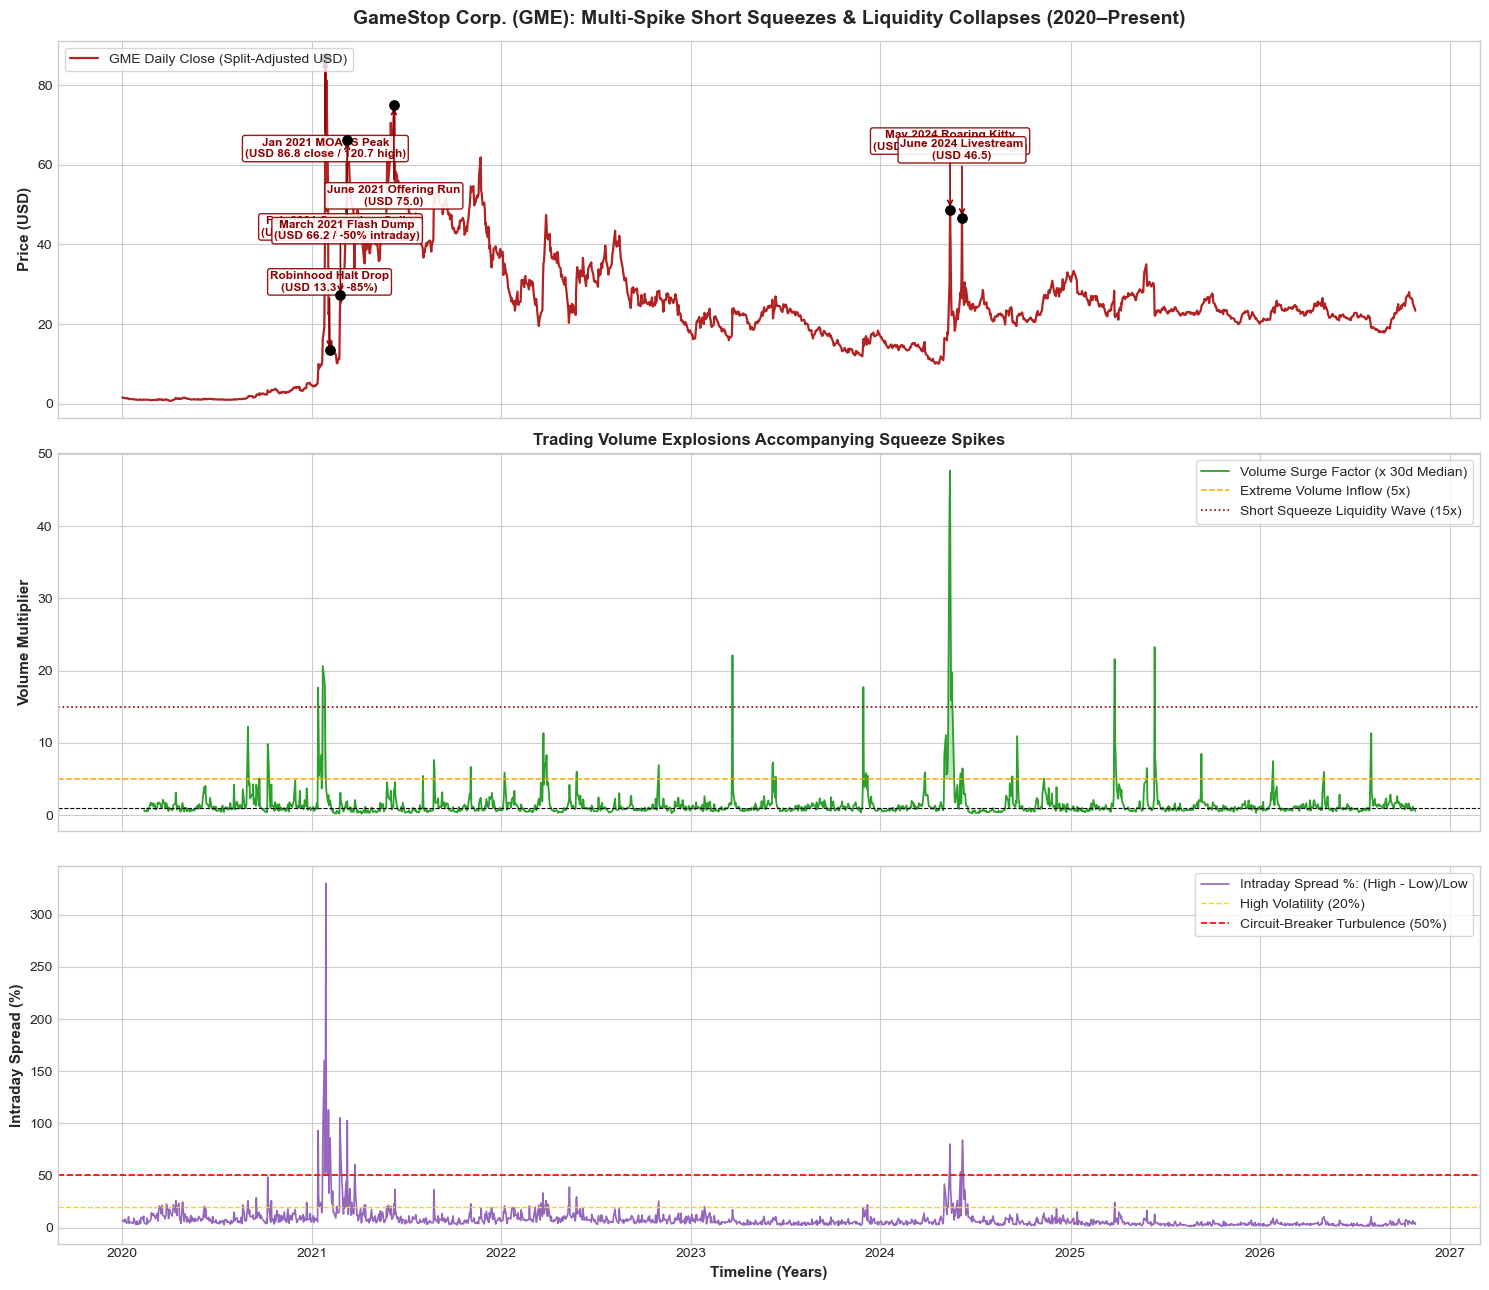

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(15, 13), sharex=True)

# 1. Price Timeline with Multi-Episode Annotations
ax1 = axes[0]
ax1.plot(df_gme_proc['date'], df_gme_proc['GME_close'], color='#b22222', lw=1.6, label='GME Daily Close (Split-Adjusted USD)')
ax1.set_title("GameStop Corp. (GME): Multi-Spike Short Squeezes & Liquidity Collapses (2020–Present)", 
              fontsize=14, fontweight='bold', pad=12)
ax1.set_ylabel("Price (USD)", fontsize=11, fontweight='bold')

gme_episodes = [
    ('2021-01-27', 'Jan 2021 MOASS Peak\n(USD 86.8 close / 120.7 high)', 86.8),
    ('2021-02-04', 'Robinhood Halt Drop\n(USD 13.3 / -85%)', 13.3),
    ('2021-02-25', 'Feb 2021 Secondary Spike\n(USD 27.1 / +18% to USD 45)', 27.1),
    ('2021-03-10', 'March 2021 Flash Dump\n(USD 66.2 / -50% intraday)', 66.2),
    ('2021-06-08', 'June 2021 Offering Run\n(USD 75.0)', 75.0),
    ('2024-05-14', 'May 2024 Roaring Kitty\n(USD 48.7 close / 64.8 high)', 48.7),
    ('2024-06-06', 'June 2024 Livestream\n(USD 46.5)', 46.5)
]

for date_str, label, y_val in gme_episodes:
    dt = pd.to_datetime(date_str)
    if dt in df_gme_proc['date'].values:
        actual = df_gme_proc.loc[df_gme_proc['date'] == dt, 'GME_close'].values[0]
        ax1.scatter(dt, actual, color='black', s=45, zorder=5)
        offset_y = 15 if actual < 50 else -25
        ax1.annotate(label, xy=(dt, actual), xytext=(dt, actual + offset_y),
                     arrowprops=dict(arrowstyle="->", color='#8b0000', lw=1.2),
                     fontsize=8.5, fontweight='bold', color='#8b0000', ha='center',
                     bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.9, edgecolor='#8b0000'))

ax1.legend(loc='upper left', frameon=True)

# 2. Volume Surge Ratio (Current Vol / 30-Day Median)
ax2 = axes[1]
ax2.plot(df_gme_proc['date'], df_gme_proc['volume_surge_ratio'], color='#2ca02c', lw=1.3, label='Volume Surge Factor (x 30d Median)')
ax2.axhline(1.0, color='black', lw=0.8, ls='--')
ax2.axhline(5.0, color='orange', ls='--', lw=1.1, label='Extreme Volume Inflow (5x)')
ax2.axhline(15.0, color='darkred', ls=':', lw=1.2, label='Short Squeeze Liquidity Wave (15x)')
ax2.fill_between(df_gme_proc['date'], 5.0, df_gme_proc['volume_surge_ratio'], 
                 where=(df_gme_proc['volume_surge_ratio'] >= 5.0), color='#2ca02c', alpha=0.3)
ax2.set_ylabel("Volume Multiplier", fontsize=11, fontweight='bold')
ax2.set_title("Trading Volume Explosions Accompanying Squeeze Spikes", fontsize=12, fontweight='bold')
ax2.legend(loc='upper right', frameon=True)

# 3. Intraday High-Low Volatility Spread (%)
ax3 = axes[2]
ax3.plot(df_gme_proc['date'], df_gme_proc['intraday_spread_pct'], color='#9467bd', lw=1.2, label='Intraday Spread %: (High - Low)/Low')
ax3.axhline(20.0, color='gold', ls='--', lw=1.0, label='High Volatility (20%)')
ax3.axhline(50.0, color='red', ls='--', lw=1.2, label='Circuit-Breaker Turbulence (50%)')
ax3.fill_between(df_gme_proc['date'], 50.0, df_gme_proc['intraday_spread_pct'], 
                 where=(df_gme_proc['intraday_spread_pct'] >= 50.0), color='purple', alpha=0.3)
ax3.set_ylabel("Intraday Spread (%)", fontsize=11, fontweight='bold')
ax3.set_xlabel("Timeline (Years)", fontsize=11, fontweight='bold')
ax3.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.savefig('data/gamestop_spikes_timeline.png', dpi=300)
plt.show()

### 7. Squeeze Episode Breakdown Table & Processed Export

In [5]:
# Summary table of the top 10 single-day percentage gains in GME
top_gme_gains = df_gme_proc.sort_values('return_pct', ascending=False).head(10)[['date', 'GME_close', 'return_pct', 'intraday_spread_pct', 'volume_surge_ratio']]
top_gme_gains['date'] = top_gme_gains['date'].dt.strftime('%Y-%m-%d')
print("=== Top 10 Single-Day GameStop Squeeze Jumps ===")
print(top_gme_gains.to_string(index=False))

# Export clean processed dataset
out_path = 'data/gamestop_spikes_processed.csv'
df_gme_proc.to_csv(out_path, index=False)
print(f"\nProcessed GameStop dataset successfully saved to: {out_path}")

=== Top 10 Single-Day GameStop Squeeze Jumps ===
      date  GME_close  return_pct  intraday_spread_pct  volume_surge_ratio
2021-01-27  86.877502  134.835802            52.610442            9.325868
2021-02-24  22.927500  103.935950           105.167780            1.855899
2021-01-26  36.994999   92.707376            87.032426           17.963708
2024-05-13  30.450001   74.398639            54.218813           43.150706
2021-01-29  81.250000   67.871896            65.592004            3.207817
2024-05-14  48.750000   60.098518            80.083338           47.699280
2021-01-13   7.850000   57.393476            92.960560           17.638614
2021-03-25  45.937500   52.692376            60.393497            2.086259
2021-01-22  16.252501   51.080651            81.379969           20.625908
2024-06-06  46.549999   47.450110            51.854217            5.176916

Processed GameStop dataset successfully saved to: data/gamestop_spikes_processed.csv
